# HW10 Part 2: Exploratory and descriptive analysis
**Project F1: Moodle Activity, Marina Gorelikova**

Here we look at how students and teachers used Moodle from 2019 to 2026.

We count activity in active days. An active day is a day when a student did at least one thing in Moodle. We don't count events, because about 15% of the event rows are duplicates and a few students have a huge number of events.

All numbers are per student. We divide by the number of students in grades for that year, so students who never opened Moodle are also included.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../results/figures", exist_ok=True)   # folder for poster figures

years = [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

events_list = []
grades_list = []
calendar_list = []

for year in years:
    events_list.append(pd.read_parquet("../data/data/" + str(year) + "/events.parquet"))
    grades_list.append(pd.read_csv("../data/data/" + str(year) + "/grades.csv"))
    calendar_list.append(pd.read_csv("../data/data/" + str(year) + "/calendar.csv"))

events = pd.concat(events_list, ignore_index=True)
grades = pd.concat(grades_list, ignore_index=True)
calendar = pd.concat(calendar_list, ignore_index=True)
course_runs = pd.read_csv("../data/data/course_runs.csv")

print("events:", events.shape)
print("grades:", grades.shape)
print("calendar:", calendar.shape)
print("course_runs:", course_runs.shape)

/Users/marinagorelikova/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/marinagorelikova/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


events: (972372, 9)
grades: (945, 41)
calendar: (750, 5)
course_runs: (8, 9)


In [2]:
# Year in all tables (TCS_2019 -> 2019)
for df in [events, grades, calendar, course_runs]:
    df["year"] = df["course_run_id"].str[-4:].astype(int)

# Calendar date of each event (time is already in Tallinn time zone)
events["date"] = events["event_time"].dt.tz_localize(None).dt.normalize()

In [3]:
# Add a "year" column to all four tables
for df in [events, grades, calendar, course_runs]:
    df["year"] = df["course_run_id"].str[-4:].astype(int)

print(events["year"].value_counts().sort_index())

year
2019     68072
2020    122142
2021    183166
2022     97830
2023    121861
2024    157788
2025    112864
2026    108649
Name: count, dtype: int64


In [4]:
# Only students
students = events[events["actor_id"] != "T"].copy()

# Week of the semester: week 1 = first 7 days from the course start
start = pd.to_datetime(course_runs.set_index("year")["course_start_date"])
students["week"] = (students["date"] - students["year"].map(start)).dt.days // 7 + 1

In [5]:
# One row = one student active on one day
student_days = students[["year", "actor_id", "date", "week"]].drop_duplicates()

# Number of students in each year (from grades: includes students with no activity)
n_students = grades.groupby("year").size()

# Average active days per student in each week
weekly = student_days.groupby(["week", "year"]).size().unstack()
weekly = weekly / n_students
weekly = weekly.loc[1:18]

In [6]:
# One row = one student active on one day
student_days = students[["year", "actor_id", "date", "week"]].drop_duplicates()

# Number of students in each year (from grades: includes students with no activity)
n_students = grades.groupby("year").size()

# Active days per week, divided by the number of students -> average per student
weekly = student_days.groupby(["week", "year"]).size().unstack()
weekly = weekly / n_students
weekly = weekly.loc[1:18]

weekly.round(2).head()

year,2019,2020,2021,2022,2023,2024,2025,2026
week,,,,,,,,
1,1.56,NaN,1.56,1.61,2.01,2.23,2.08,2.15
2,2.14,1.54,2.82,2.40,2.36,2.46,2.16,1.89
3,2.22,1.38,2.61,2.22,2.31,2.89,1.99,2.41
4,2.87,2.17,3.15,2.51,3.03,3.01,2.39,1.93
5,2.90,2.95,3.42,2.59,3.25,3.26,3.03,2.86


In [7]:
# Sanity check: log period vs course start, and weekly totals vs total active days per student
check = students.groupby("year")["date"].agg(["min", "max"])
check["course_start_date"] = course_runs.set_index("year")["course_start_date"]
check["median active days per student"] = student_days.groupby(["year", "actor_id"]).size().groupby("year").median()
check["sum of weekly averages (weeks 1-18)"] = weekly.sum().round(1)
check

,min,max,course_start_date,median active days per student,sum of weekly averages (weeks 1-18)
year,,,,,
2019,2019-02-11,2019-06-28,2019-02-11,49.0,49.7
2020,2020-02-19,2020-06-26,2020-02-10,58.0,55.5
2021,2021-02-10,2021-06-26,2021-02-08,63.5,58.7
2022,2022-02-07,2022-06-23,2022-02-07,52.5,48.9
2023,2023-02-06,2023-06-24,2023-02-06,55.5,53.4
2024,2024-02-12,2024-06-30,2024-02-12,56.0,58.7
2025,2025-02-10,2025-06-28,2025-02-10,50.0,50.3
2026,2026-02-09,2026-06-28,2026-02-09,52.0,49.2


In most years the logs start on the first day of the course. In 2020 they start 9 days later and in 2021 two days later. When we add up the weekly averages, we get almost the same number as the median of active days per student. So the weekly numbers look correct.

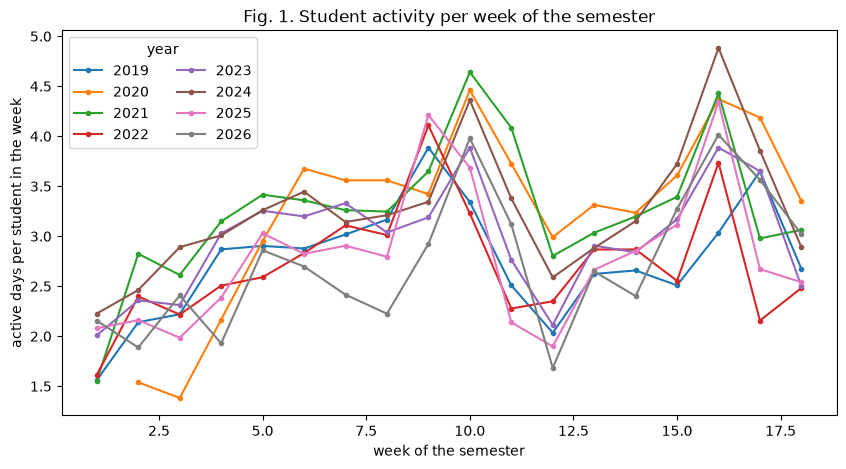

In [8]:
ax = weekly.plot(figsize=(10, 5), marker="o", markersize=3)
ax.set_title("Fig. 1. Student activity per week of the semester")
ax.set_xlabel("week of the semester")
ax.set_ylabel("active days per student in the week")
ax.legend(title="year", ncol=2)
plt.savefig("../results/figures/fig1_weekly_activity.pdf", bbox_inches="tight")
plt.show()

Students are most active in week 9 or 10, when the first midterm is, and in week 16, when the exam is. Right after the midterm, in week 12, activity goes down a lot. At the start of the semester students use Moodle about 2 days a week, and later about 3.

The first weeks of 2020 are lower than other years, but this is because the logs start later. In 2024 students were the most active before the exam, almost 5 days a week. The midterm is not in the same week every year, so in the next figure we count weeks from the midterm to make years easier to compare.

## Weekly activity aligned to the first midterm
The midterm is not in the same week every year. Here we count weeks from the first midterm, so week 0 is the midterm week in every year. We also split the years by course format.

In [9]:
# Date of the first midterm in each year 
mid = calendar[calendar["activity_name"] == "midterm_attempt_1"].copy()
mid["midterm_date"] = pd.to_datetime(mid["start_time"].str[:10])
midterm = mid.groupby("year")["midterm_date"].min()

# Course format from our plan, next to delivery_mode from the data
FORMAT = {2019: "in-person", 2020: "remote", 2021: "remote", 2022: "hybrid",
          2023: "hybrid", 2024: "hybrid", 2025: "in-person", 2026: "in-person"}

info = course_runs.set_index("year")[["delivery_mode"]].copy()
info["format in our plan"] = info.index.map(FORMAT)
info["first midterm"] = midterm.dt.date
info["midterm week"] = (midterm - start).dt.days // 7 + 1
info

,delivery_mode,format in our plan,first midterm,midterm week
year,,,,
2019,in_person,in-person,2019-04-15,10
2020,remote,remote,2020-04-17,10
2021,remote,remote,2021-04-16,10
2022,hybrid,hybrid,2022-04-08,9
2023,hybrid,hybrid,2023-04-14,10
2024,hybrid,hybrid,2024-04-19,10
2025,in_person,in-person,2025-04-11,9
2026,in_person,in-person,2026-04-17,10


In [10]:
# Weeks from the first midterm: 0 = the 7 days starting on the midterm day, -1 = the week before
student_days["week_mid"] = (student_days["date"] - student_days["year"].map(midterm)).dt.days // 7

weekly_mid = student_days.groupby(["week_mid", "year"]).size().unstack()
weekly_mid = weekly_mid / n_students
weekly_mid = weekly_mid.loc[-8:7]

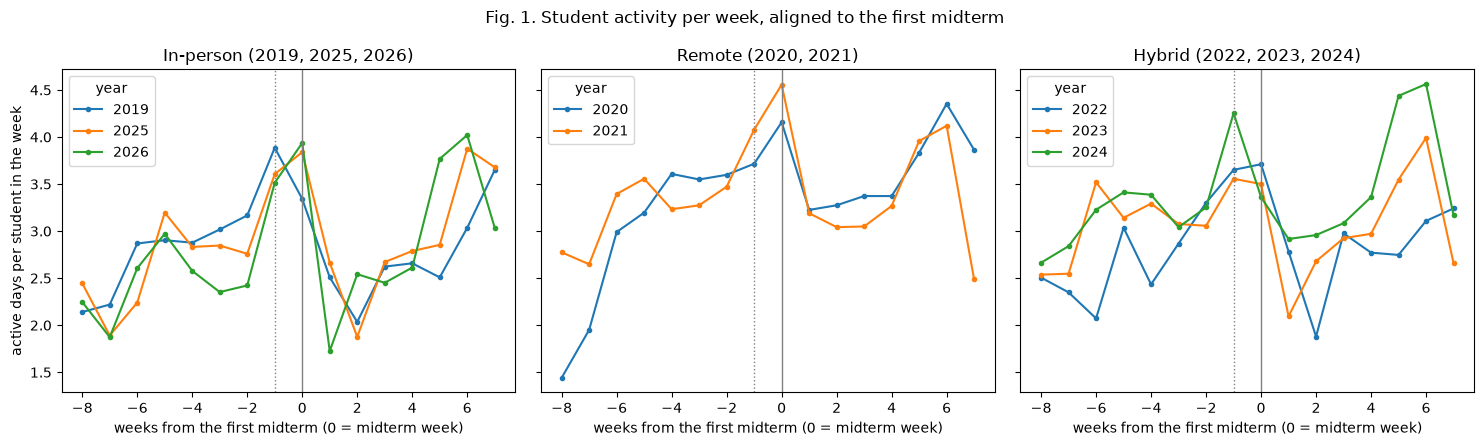

In [11]:
 groups = {
    "In-person (2019, 2025, 2026)": [2019, 2025, 2026],
    "Remote (2020, 2021)": [2020, 2021],
    "Hybrid (2022, 2023, 2024)": [2022, 2023, 2024],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (title, group_years) in zip(axes, groups.items()):
    for y in group_years:
        ax.plot(weekly_mid.index, weekly_mid[y], marker="o", markersize=3, label=str(y))
    ax.axvline(0, color="gray", linewidth=1)                    # midterm week
    ax.axvline(-1, color="gray", linewidth=1, linestyle=":")    # prediction cutoff
    ax.set_title(title)
    ax.set_xlabel("weeks from the first midterm (0 = midterm week)")
    ax.legend(title="year")

axes[0].set_ylabel("active days per student in the week")
fig.suptitle("Fig. 1. Student activity per week, aligned to the first midterm")
plt.tight_layout()
plt.savefig("../results/figures/fig1_weekly_activity_by_format.pdf", bbox_inches="tight")
plt.show()

After we align the weeks to the first midterm, all years have the same shape. Activity grows until the midterm, drops a lot one or two weeks after it, and grows again before the exam.

The formats are different in the level of activity. Before the prediction cutoff, students in remote years used Moodle about 3 to 3.6 days a week, and in in-person years about 2 to 3 days. After the midterm, activity in remote years stayed around 3 days a week, but in in-person years it fell to about 2. In 2024 the peaks were the highest. 2022 jumps more than other years, but it also had the smallest group of students (83).

In 2019 the midterm was on a Monday, and in other years on a Friday, so the peak in 2019 is one week earlier.

This is important for the model: the level of activity before the cutoff is different in different years. A rule like "less than X active days means risk" learned on older years may not work on 2025 and 2026.

## Active days per student in the whole semester

In [12]:
# All students from grades (also those who never opened Moodle)
roster = grades[["year", "actor_id"]].drop_duplicates()

# Active days of each student in the whole semester
days = student_days.groupby(["year", "actor_id"]).size().rename("active_days").reset_index()

# Join: students without any activity get 0 active days
per_student = roster.merge(days, on=["year", "actor_id"], how="left")
per_student["active_days"] = per_student["active_days"].fillna(0)

# Summary table by year
summary = per_student.groupby("year")["active_days"].agg(["count", "median", "mean"])
summary["no activity"] = per_student["active_days"].eq(0).groupby(per_student["year"]).sum()
summary.insert(0, "format", summary.index.map(FORMAT))
summary.round(1)

,format,count,median,mean,no activity
year,,,,,
2019,in-person,114,49.0,50.0,0
2020,remote,102,57.0,56.8,3
2021,remote,142,62.5,60.2,2
2022,hybrid,83,52.0,49.9,1
2023,hybrid,106,55.5,55.2,0
2024,hybrid,119,56.0,60.5,0
2025,in-person,137,50.0,52.1,0
2026,in-person,142,52.0,51.3,1


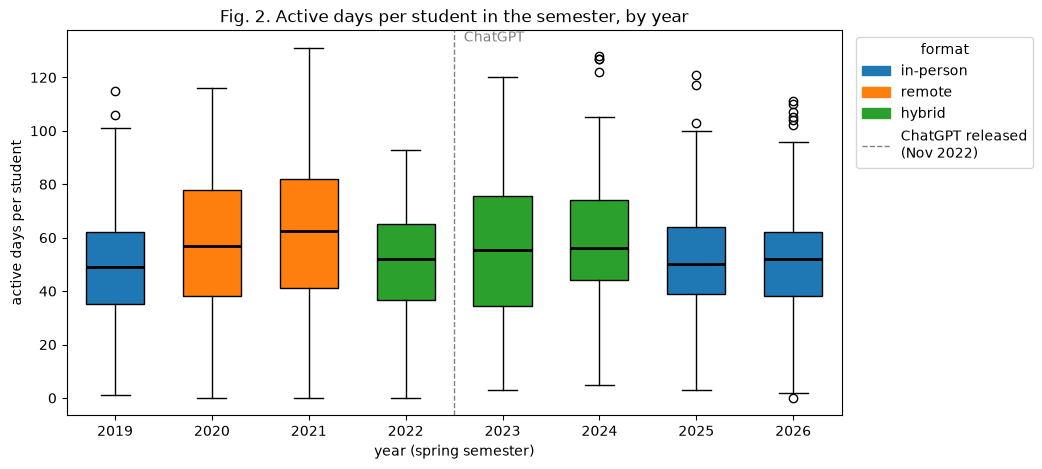

In [16]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

colors = {"in-person": "tab:blue", "remote": "tab:orange", "hybrid": "tab:green"}
data = [per_student.loc[per_student["year"] == y, "active_days"] for y in years]

fig, ax = plt.subplots(figsize=(10, 5))

# Each box stands at its year on the x axis (2019, 2020, ...)
box = ax.boxplot(data, positions=years, widths=0.6, patch_artist=True,
                 medianprops=dict(color="black", linewidth=2))
ax.set_xticks(years)

# Color of each box = course format of that year
for patch, y in zip(box["boxes"], years):
    patch.set_facecolor(colors[FORMAT[y]])

# Line between 2022 and 2023: ChatGPT appeared in November 2022
ax.axvline(2022.5, color="gray", linestyle="--", linewidth=1)
ax.text(2022.6, ax.get_ylim()[1], "ChatGPT", va="top", color="gray")

ax.set_title("Fig. 2. Active days per student in the semester, by year")
ax.set_xlabel("year (spring semester)")
ax.set_ylabel("active days per student")
legend_items = [Patch(color=c, label=f) for f, c in colors.items()]
legend_items.append(Line2D([0], [0], color="gray", linestyle="--", linewidth=1,
                           label="ChatGPT released\n(Nov 2022)"))
ax.legend(handles=legend_items, title="format", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.savefig("../results/figures/fig2_active_days_by_year.pdf", bbox_inches="tight")
plt.show()

The median student was active on 49 to 62.5 days in the semester. Remote years were the highest (median 57 in 2020 and 62.5 in 2021), hybrid years were in the middle (52 to 56), and in-person years were the lowest (49 to 52).

The difference between years is small compared to the difference between students in the same year. The medians differ by about 13 days at most, but the middle half of students in one year can differ by 25 to 40 days. So individual students differ much more than years do.

ChatGPT was released in November 2022, after the spring semester of 2022, so 2023 is the first year when students could use it. We don't see a clear change after ChatGPT appeared: from 2022 to 2023 the median grew only by 3.5 days. The changes match the course format better.

Almost all students used Moodle. Only 0 to 3 students per year had no activity at all.